# Лабораторная работа 6

Адаптивное планирование по событиям.

**Цель:** принимать изменения мира и пересматривать только затронутые назначения. Выполнены три основных сценария и все три самостоятельных задания.

Запускайте ячейки сверху вниз. Здесь собран весь код, отдельные `.py` не нужны. Зависимости: `pip install thespian openpyxl matplotlib`. Прежние notebooks сохранены. Собственный Excel на три заказа и два курьера встроен ниже. Если рядом уже есть входной файл и JSON, используются они без перезаписи.

Это события изменения **будущего плана** при неизменном t0. Ход реальных доставок и продвижение модельных часов здесь не имитируются. События подаются по одному после завершения предыдущих переговоров.

## 1 Исходные данные и настройки

Есть обычные заказы и ночной заказ, два курьера с разными типами грузов. Для срочного заказа исполнителя сначала нет. Критерии, свертка и конфликты сохранены из ЛР5; веса получения, доставки и стоимости равны 0,2; 0,3; 0,5. Окна — пожелания, а не жесткие ограничения всех вариантов.

In [1]:
from pathlib import Path
import base64
import json
import logging

Path('Отчёты').mkdir(exist_ok=True)
input_bytes=base64.b64decode('UEsDBBQAAAAIAF2BZF1Gx01IlQAAAM0AAAAQAAAAZG9jUHJvcHMvYXBwLnhtbE3PTQvCMAwG4L9SdreZih6kDkQ9ip68zy51hbYpbYT67+0EP255ecgboi6JIia2mEXxLuRtMzLHDUDWI/o+y8qhiqHke64x3YGMsRoPpB8eA8OibdeAhTEMOMzit7Dp1C5GZ3XPlkJ3sjpRJsPiWDQ6sScfq9wcChDneiU+ixNLOZcrBf+LU8sVU57mym/8ZAW/B7oXUEsDBBQAAAAIAF2BZF1dqhsq7gAAACsCAAARAAAAZG9jUHJvcHMvY29yZS54bWzNks9KxDAQh19Fcm8n6eqCoduL4klBcEHxFpLZ3WDzh2Sk3bc3rbtdRB/AY2Z++eYbmFZHqUPC5xQiJrKYr0bX+yx13LADUZQAWR/QqVyXhC/NXUhOUXmmPUSlP9QeoeF8DQ5JGUUKJmAVFyLrWqOlTqgopBPe6AUfP1M/w4wG7NGhpwyiFsC6aWI8jn0LF8AEI0wufxfQLMS5+id27gA7Jcdsl9QwDPWwmnNlBwFvT48v87qV9ZmU11h+ZSvpGHHDzpNfV3f32wfWNbxZV0JU/HorGim4vLl9n1x/+F2EXTB2Z/+x8Vmwa+HXXXRfUEsDBBQAAAAIAF2BZF36XAFZ/AIAANoNAAATAAAAeGwvdGhlbWUvdGhlbWUxLnhtbLVX2VLbMBT9FY/fi7wvGQLDkrQP7bRT+AHFlpciyx5LIfD3lRUvsh2FsCTMgCWdc8+x7tVVuLx+KbD2jGqal2SpmxeGriESlXFO0qW+Zcm3QL++uoQLlqECaQQWaKnfZZB9//Ooa5xL6AIu9YyxagEAjTgK0ouyQoSvJWVdQMaHdQriGu54zAIDyzA8UMCc6H3cFea/CKPNRITrh+iAWLMWP5nNH/pK73CtPUO81HnQuNw9ohemaxhSxheWuiE+ugauLkHPwkxBlohr8emILSN+sgSxTjc901hZgWMOCtZeYQ5cBc3PEFEgYBTx1zVnYNP1jMDqwBJq/3ggeuib9oQgKdhzhdC7tZwxwR4IzvxF1+Hq3h0TnIHgzgg3hnUb2mOCOxC8GcFZ3fjWakwQqAzn5GkO9/wg8Dp4j0lK/OMgPvQ8w7/v8AMMSKW2D0DYqPB+J0keIVF3BfxX1msOEFmGLCcae61QAqOmQCHON3Wu/czTjAkduEDwDUBEjwLARLPIyZsGjkgfEe3lBgUgb4bYmoIpj2SSY/zAXjH6SYU5WuI8XvNJMRCsPhVVxh87wREwreHwTNtQKdWqkvIS1JWxRAfJCdvPeX536vkmbYtfZdwWvWkMCxSyYcFwpT7RK4hRSmUProhwog/fVvgY5KY+7BN9mMZ7jATmu42ER40AKT38GGmwuSVcp223NIIYxU3C2gCjtH5JikNH9UbWZ7f2hBTTDMaoi2uonKiKzTS+MMmSFT847CQMFUas40Y+nGQwbweYjEfartH3u7f7ULOoasruIc32OLHU369Ekgl5lZ9fxmp25nwyYLqHKElQxBQzw5CvtVEOLn8W3QzKLUP1QxbvtA3e1n8hLwrXN/mea3FOWZcAPqiH8pl/vxjmIa4y2Hby0aHd48VzrymZFXam1sGhndqk6y+5rt5mTbqWqt366pN4hvsxlO4lqX+Eiv6h7qnuqZ3sXdem7EO2p2y0tsKefaZG66kEz9hQpyULpK9jYjT5B6qbufoPUEsDBBQAAAAIAF2BZF1e8wZLQwMAAA8RAAAYAAAAeGwvd29ya3NoZWV0cy9zaGVldDEueG1s1Vhdb9sgFP0rliftsf7Csd0mkdY2bfMxqWq17dlNSGLVNhkmTfvvBxhbYDkUNdW0vQTD4VwO91xMkuEB4edqCyGxXou8rEb2lpDdueNUyy0s0uoM7WBJkTXCRUpoF2+caodhuuKkInd81x04RZqV9njIx+7xeIj2JM9KeI+tal8UKX67hDk6jGzPbgYess2WsAFnPNylG/gIyY/dPaY9p42yygpYVhkqLQzXI/ubd74AbD6f8DODh0p6tthOnhB6Zp3pamS7TBDM4ZKwCCltXuAVzHMWiMr4LWLa7ZKMKD830W/43ulentIKXqH8V7Yi25Ed29YKrtN9Th7Q4Q6K/YQs3hLlFf+0DvVcj05e7iuCCkGmCoqsrNv0VeRBIvj+EYIvCH6HcHSFQBACUwIQBGBKCAUhNCUMBGFgSogEITIlxIIQmxISQUhMCZ7bOOcaU1qzu24fpzR2e9xvpy4sXpXXKUnHQ4wOFubzWfUNBk2cth7pIViyGbzmuVd0NCvZ6XwkmKIZDUjGX794bhhcsCYe1A3gTRTVvfhi6BCqgE13liLopXHQyK/DuH2xQ3ndCCiEUOZRQo+KKwMVvhI0kRs62BP02iCoUFrvMImVPYG+oBODoDU/cRUvlLQ1g4k003PdvgVvDBZUVxo0dvPNqMuHchKFQtqzOBgpfJETr27CPruF7uDCeu1RfvtfKH/rUX7315RHKj/pzJFOU9wev95kT/9tyX1Znr0vGfiKyPZgNuadaj4HE1l6rLxmIt37Zf45+j+Uz5OELwxqJVbqIfr4ig6939pLzq8vucA/fsn5XBX7Kvoy9obOi3xX+bpUR1ptltd37WgWu9ZgEwVzXRW9kdFQxW5lrMO702BTDTbTYHNFSwdc6PLZuRoT+TyJgyQGY09nefC+5YGk0e9YHpxgud9neaCxXINNAq3lgcbyQGO5BptqsJkGmwc6y3X5/CzLwfuWA0lj0LEcGH/BVbU1b1DP6GXVVxtAUxsabAK0tQE0tQE0taHBphpspsHmQFcbpye+rygc6bcO+5vge4o3WVlZOVzT1dwz+ssQ1+XBnwna8Sd6Oz0hQoun6W1huoKY9WgNrxEiTYf9qmr/Axn/AVBLAwQUAAAACABdgWRd/ap6910DAADQDgAAGAAAAHhsL3dvcmtzaGVldHMvc2hlZXQyLnhtbOVXyW7bMBD9FUEFeowWUlu8AI2zOAEKBAnanhWbtoVIoivRcfr35SaFlClZAXrrxdSIfDPz5g1JeXrE1Wu9Q4hY70Ve1jN7R8j+0nHq1Q4VaX2B96ikMxtcFSmhZrV16n2F0jUHFbnju27oFGlW2vMpf/dYzaf4QPKsRI+VVR+KIq3+XKEcH2e2ZzcvnrLtjrAXzny6T7foGZEf+8eKWk7rZZ0VqKwzXFoV2szsb97lA2Dr+YKfGTrWyrPFmLxg/MqM+/XMdllCKEcrwjykdHhDC5TnzBFN47f0abchGVB9brzfcu6Uy0taowXOf2VrspvZsW2t0SY95OQJH5dI8gmYvxXOa/5rHcVajy5eHWqCCwmmGRRZKcb0XdZBAfh+D8CXAL8D6I0AJACMBUAJgB0AcHsAgQQEXQ6wBxBKQNgFhD2ASAKisRxiCYjHAhIJSMYCPLdRzuUdJCTn/XKdknQ+rfDRqvh61hdhS63tFNqeK7aCdyOvIn2blWzfPJOKzmbUIZl//eK5QTxhQ+SLAYgh4kPMLc91hRXwIUmE5U0s5W0cigFq+HgydQhlwMI5K5nU1fmkQhERitwCaHKzGMHN1XILm6R4itLSuMkqJG5jWYZJzTKWSEaKWku4ibQ0gLY01uoWKLl5LphY74YCXP9PBfhjKMDN6O5uSEZNB1tqBeSQdKjzAWok9d0B1f2QAOk00arja94SjbKxrW9HkIrUTGNdR9jLiWlkKaQ+EleTCnuUt9TW0Q4LiZTpJJ6J1d2IPe8bOuAzgZOuAJbiz9jt0kpgk7lanljvSGjIjuINXJejFZTdoe/LPukMke5HRIJqxZIuJ0Nxm2MeNi8NgR/OB4ZAJUVre7oB9PNAKnSS4umxcqY0Dr0e2zvSF3ck8PvvSJ+zYN+Yb3Nv6rypV5V//nCV1ATR5hz8uAB5haFRvoUa2dUjXw/M3QxmpQueqEf2yQ1uOn8GAt8NlGqpzgX63L2G6zh96JnUZATnZQSKG78jI/hHMhortgADMg7M3Qxm9RkZ+Rjoh2Jg2jhmxQdyvBuo6hIMKA6GFO+Z1BSHQ4qLlY7yScz+531Pq21W1laONnSde0E/7SuB4c8E7/kTPbVeMKEeG2tH/3Kiilk0sQ3GpDHYx3f7J3b+F1BLAwQUAAAACABdgWRd1s9qynACAADPDAAADQAAAHhsL3N0eWxlcy54bWzdV9uOmzAQ/RWLDyhJUFGoAGmLGqkvVaXdh746wRBLxqbGSUm/vh6bXNezyvalUUGRPT4+M+O5GCUfzEGw5y1jhoydkEMRbY3pP8XxsNmyjg4fVM+kRRqlO2qsqNt46DWj9QCkTsSL2SyNO8plVOZy1606M5CN2klTRLMoLvNGyfNKEvkFu5V2jOypKKKKasGNgr3Db780n4MU+523+580p+L9u9fTZpTphsFq4EJcO2wXyrynxjAtV1ZwHLf4CiLT/OXQsyJqNT3MFx+juwmDErwGk22lhNJEt+siWq2+pPA6NRfUk1I3WM/XStdMn3yfR8elMhesMZauebuF0ageQqKMUZ2d1Jy2SlJ3sCNjmli1GybEM9TJj+ZK99gQn/CvNeSaQPyOU+vQNPVqvAD6L7V53Rdq079SS3q+V+bzzp5GOvnnThn2XbOGj04em5N9TPv8X2mnfS8OT4K3smM+sncbLHN65JE904ZvoKg3VmTaxXpsHsol8kvT/oWNZmrDe/1bPKJ/iwfxL55a6KJPr7r0tErgUiyib3CTi6uqPfckaIGLx45c1mxkdTWJ9ia6uJJm0wPsW2TlnjCCcTwWRgDD7GAeYBzPwuz8T+dZoufxGObbMogsUc4S5XhWCKnci9kJczL7hE+aZUmSplhEqyroQYXFLU3hF9aG+QYMzA5Yel+s8WzjFfJ2HWA5fatCsJPilYidFI81IOG4ASPLwtnG7AADywJWO2A/bAdqKsxJEsgq5hvWwTiSZRgCtRiu0TRFopPCG84P1iVJkmVhBLCwB0mCIdCNOIJ5AD5gSJK4b9TN9yg+fqfi81+Y8g9QSwMEFAAAAAgAXYFkXZeKuxzAAAAAEwIAAAsAAABfcmVscy8ucmVsc52SuW7DMAxAf8XQnjAH0CGIM2XxFgT5AVaiD9gSBYpFnb+v2qVxkAsZeT08EtweaUDtOKS2i6kY/RBSaVrVuAFItiWPac6RQq7ULB41h9JARNtjQ7BaLD5ALhlmt71kFqdzpFeIXNedpT3bL09Bb4CvOkxxQmlISzMO8M3SfzL38ww1ReVKI5VbGnjT5f524EnRoSJYFppFydOiHaV/Hcf2kNPpr2MitHpb6PlxaFQKjtxjJYxxYrT+NYLJD+x+AFBLAwQUAAAACABdgWRdWSpU99QAAACqAQAADwAAAHhsL3dvcmtib29rLnhtbLVQOwrCQBC9StgDuJrCIiSpbGzEK6zZiVmS3Q0z66cULLUXPIWNCJ4iuZEbNWAlNhbzfcObx4s3FsuFtWWw1ZWhhBXO1RHnlBWgBQ1sDcYjuUUtnB9xyalGEJIKAKcrHg6HY66FMiyNe6458jR+HtC7vtgj/IXf5rnKYGKzlQbjXg8QKuGUNVSomlhghIaENafm0tx93NoDC55/pjJhI9874fzBWpFaVMACjJQHcCpHjP9V0bndt7v22Fx9/tQUftEUdpp4b5eEXBmQM89H3b73NH0AUEsDBBQAAAAIAF2BZF2N9yxatAAAAIkCAAAaAAAAeGwvX3JlbHMvd29ya2Jvb2sueG1sLnJlbHPFkk0KgzAQRq8ScoCO2tJFUVfduC1eIOj4g9GEzJTq7Wt1oYEuupGuwjch73swiR+oFbdmoKa1JMZeD5TIhtneAKhosFd0MhaH+aYyrlc8R1eDVUWnaoQoCK7g9gyZxnumyCeLvxBNVbUF3k3x7HHgL2B4GddRg8hS5MrVyImEUW9jguUITzNZiqxMpMvKUMK/hSJPKDpQiHjSSJvNmr3684H1PL/FrX2J69DfyeXjAN7PS99QSwMEFAAAAAgAXYFkXW6nJLweAQAAVwQAABMAAABbQ29udGVudF9UeXBlc10ueG1sxZTPTsMwDMZfpcp1ajJ24IDWXYAr7MALhNZdo+afYm90b4/bbpNAo2IqEpdGje3v5/iLsn47RsCsc9ZjIRqi+KAUlg04jTJE8BypQ3Ka+DftVNRlq3egVsvlvSqDJ/CUU68hNusnqPXeUvbc8Taa4AuRwKLIHsfEnlUIHaM1pSaOq4OvvlHyE0Fy5ZCDjYm44AShrhL6yM+AU93rAVIyFWRbnehFO85SnVVIRwsopyWu9Bjq2pRQhXLvuERiTKArbADIWTmKLqbJxBOG8Xs3mz/ITAE5c5tCRHYswe24syV9dR5ZCBKZ6SNeiCw9+3zQu11B9Us2j/cjpHbwA9WwzJ/xV48v+jf2sfrHPt5DaP/6qverdNr4M18N78nmE1BLAQIUAxQAAAAIAF2BZF1Gx01IlQAAAM0AAAAQAAAAAAAAAAAAAACAAQAAAABkb2NQcm9wcy9hcHAueG1sUEsBAhQDFAAAAAgAXYFkXV2qGyruAAAAKwIAABEAAAAAAAAAAAAAAIABwwAAAGRvY1Byb3BzL2NvcmUueG1sUEsBAhQDFAAAAAgAXYFkXfpcAVn8AgAA2g0AABMAAAAAAAAAAAAAAIAB4AEAAHhsL3RoZW1lL3RoZW1lMS54bWxQSwECFAMUAAAACABdgWRdXvMGS0MDAAAPEQAAGAAAAAAAAAAAAAAAgIENBQAAeGwvd29ya3NoZWV0cy9zaGVldDEueG1sUEsBAhQDFAAAAAgAXYFkXf2qevddAwAA0A4AABgAAAAAAAAAAAAAAICBhggAAHhsL3dvcmtzaGVldHMvc2hlZXQyLnhtbFBLAQIUAxQAAAAIAF2BZF3Wz2rKcAIAAM8MAAANAAAAAAAAAAAAAACAARkMAAB4bC9zdHlsZXMueG1sUEsBAhQDFAAAAAgAXYFkXZeKuxzAAAAAEwIAAAsAAAAAAAAAAAAAAIABtA4AAF9yZWxzLy5yZWxzUEsBAhQDFAAAAAgAXYFkXVkqVPfUAAAAqgEAAA8AAAAAAAAAAAAAAIABnQ8AAHhsL3dvcmtib29rLnhtbFBLAQIUAxQAAAAIAF2BZF2N9yxatAAAAIkCAAAaAAAAAAAAAAAAAACAAZ4QAAB4bC9fcmVscy93b3JrYm9vay54bWwucmVsc1BLAQIUAxQAAAAIAF2BZF1upyS8HgEAAFcEAAATAAAAAAAAAAAAAACAAYoRAABbQ29udGVudF9UeXBlc10ueG1sUEsFBgAAAAAKAAoAhAIAANkSAAAAAA==')
if not Path('Исходные данные_ЛР6.xlsx').exists():
    Path('Исходные данные_ЛР6.xlsx').write_bytes(input_bytes)
config_text='{\n  "default_profile": "ЛР6",\n  "criteria": [\n    {\n      "name": "start_efficiency",\n      "field": "pickup",\n      "direction": "decreasing"\n    },\n    {\n      "name": "finish_efficiency",\n      "field": "time_to",\n      "direction": "decreasing"\n    },\n    {\n      "name": "price_efficiency",\n      "field": "price",\n      "direction": "decreasing"\n    },\n    {\n      "name": "pickup_accuracy_efficiency",\n      "field": "pickup_deviation",\n      "direction": "decreasing"\n    }\n  ],\n  "profiles": {\n    "ЛР6": {\n      "start_efficiency": 0.2,\n      "finish_efficiency": 0.3,\n      "price_efficiency": 0.5,\n      "pickup_accuracy_efficiency": 0\n    }\n  }\n}\n'
if not Path('planning_config.json').exists():
    Path('planning_config.json').write_text(config_text,encoding='utf-8')
logging.basicConfig(level=logging.INFO,format='%(message)s',force=True,
    handlers=[logging.FileHandler('output_lab6.txt',encoding='utf-8',mode='w')])


## 2 Сцена и жизненный цикл

У BaseEntity появился is_deleting. Scene возвращает только активные сущности. ActorExitRequest обрабатывается раньше проверки пользовательского Message. ReferenceBook удаляет адрес завершенного агента. Номера и имена активных сущностей уникальны в пределах своего типа.

**message.py**

In [2]:
"""Сообщения протокола планирования ЛР6."""

from dataclasses import dataclass
from enum import Enum
from typing import Any


class MessageType(Enum):
    NEW_COURIER = 'Новый курьер'
    DELETED_COURIER = 'Курьер удален'
    RELEASE_ORDER = 'Освободить записи заказа'
    PARAMETERS_CHANGED = 'Параметры изменены'
    START_PLANNING = 'Начать переговоры'
    REMOVE_ORDER = 'Удаление заказа'
    CONSENT_REQUEST = 'Запрос согласия'
    CONSENT_RESPONSE = 'Ответ о согласии'
    INIT_MESSAGE = 'Инициализация'
    PRICE_REQUEST = 'Запрос параметров'
    PRICE_RESPONSE = 'Ответ с параметрами'
    PLANNING_REQUEST = 'Запрос планирования'
    PLANNING_RESPONSE = 'Результат планирования'


@dataclass
class Message:
    msg_type: MessageType
    msg_body: Any = None


**point.py**

In [3]:
"""Точка и евклидово расстояние."""

import math
from dataclasses import dataclass


@dataclass
class Point:
    x: float
    y: float

    def __repr__(self):
        return f'({self.x:g}; {self.y:g})'

    def get_distance_to_other(self, other_point):
        return math.dist((self.x, self.y), (other_point.x, other_point.y))


**scene.py**

In [4]:
"""Сцена сущностей виртуального мира."""

from collections import defaultdict


class Scene:
    def __init__(self):
        self.entities = defaultdict(list)

    def get_entities_by_type(self, entity_type):
        return [entity for entity in self.entities.get(entity_type, []) if not entity.is_deleting]


**entities/base_entity.py**

In [5]:
class BaseEntity:
    def __init__(self, onto_desc, scene=None):
        self.onto_description = onto_desc
        self.name = onto_desc.get('data', {}).get('label', {}).get('value')
        self.uri = 'UNKNOWN_URI'
        self.scene = scene
        self.is_deleting = False


**entities/order_entity.py**

In [6]:
class OrderEntity(BaseEntity):
    def __init__(self, onto_desc, init_dict_data, scene=None):
        super().__init__(onto_desc, scene)
        self.number = init_dict_data['Номер']
        self.name = init_dict_data['Наименование']
        self.weight = float(init_dict_data['Масса'])
        self.volume = float(init_dict_data['Объем'])
        self.price = float(init_dict_data['Стоимость'])
        self.point_from = Point(float(init_dict_data['Координата получения x']),
                                float(init_dict_data['Координата получения y']))
        self.point_to = Point(float(init_dict_data['Координата доставки x']),
                              float(init_dict_data['Координата доставки y']))
        self.time_from = float(init_dict_data['Время получения заказа'])
        self.time_to = float(init_dict_data['Время доставки заказа'])
        self.order_type = init_dict_data['Тип заказа']
        self.uri = 'Order' + str(self.number)
        self.assigned_courier = None
        self.selected_variant = None

    def get_type(self):
        return 'ORDER'


**schedule_item.py**

In [7]:
from dataclasses import dataclass



@dataclass
class ScheduleItem:
    order: OrderEntity
    rec_type: str
    start_time: float
    end_time: float
    point_from: Point
    point_to: Point
    cost: float
    all_params: dict


**reference_book.py**

In [8]:
import logging


class ReferenceBook:
    def __init__(self):
        self.agents_entities = {}

    def add_agent(self, entity, agent_address):
        self.agents_entities[entity] = agent_address

    def get_address(self, entity):
        address = self.agents_entities.get(entity)
        if address is None:
            logging.error('Агент %s отсутствует в адресной книге', entity.uri)
        return address

    def remove_agent(self, entity):
        self.agents_entities.pop(entity, None)


**agent_base.py**

In [9]:
"""Базовый агент: подписки, диспетчеризация и инициализация."""

import logging

from thespian.actors import Actor, ActorExitRequest



class AgentBase(Actor):
    def __init__(self):
        self.name = type(self).__name__
        self.handlers = {}
        self.subscribe(MessageType.INIT_MESSAGE, self.handle_init_message)

    def subscribe(self, msg_type, handler):
        self.handlers[msg_type] = handler

    def receiveMessage(self, message, sender):
        if isinstance(message, ActorExitRequest):
            self.handle_delete_message()
            return
        if not isinstance(message, Message):
            return
        if hasattr(self, 'entity'):
            self.dispatcher.notified_agents.add(self.entity.uri)
        handler = self.handlers.get(message.msg_type)
        if handler is None:
            logging.warning('%s: нет обработчика %s', self.name, message.msg_type)
            return
        logging.info('%s <- %s: %s', self.name, sender, message.msg_type.value)
        try:
            handler(message, sender)
        except Exception:
            logging.exception('Ошибка обработки сообщения агентом %s', self.name)
            raise

    def handle_init_message(self, message, sender):
        self.scene = message.msg_body['scene']
        self.dispatcher = message.msg_body['dispatcher']
        self.entity = message.msg_body['entity']
        self.name += ' ' + self.entity.name

    def handle_delete_message(self):
        self.entity.is_deleting = True

    def send(self, target, message):
        self.dispatcher.message_counts[message.msg_type.value] += 1
        super().send(target, message)

    @staticmethod
    def get_decreasing_kpi_value(value, min_value, max_value):
        if max_value == min_value:
            return 1
        if value > max_value or value < min_value:
            return -1
        if abs(value - min_value) < 0.000001:
            return 1
        if abs(value - max_value) < 0.000001:
            return 0
        return 1 - (value - min_value) / (max_value - min_value)

    @staticmethod
    def get_increasing_kpi_value(value, min_value, max_value):
        if max_value == min_value:
            return 1
        if value > max_value or value < min_value:
            return -1
        if abs(value - min_value) < 0.000001:
            return 0
        if abs(value - max_value) < 0.000001:
            return 1
        return (value - min_value) / (max_value - min_value)


## 3 Расписание и освобождение интервала

CourierEntity из ЛР5 дополнен вариантом gap для свободных интервалов. Проверяются время и пространственная непрерывность маршрута. При удалении заказа снимаются все его записи. Если это нарушило начало следующего маршрута, зависимый хвост освобождается и его заказы перепланируются. Если разрыва нет, соседние назначения сохраняются. Черновик фиксирует только измененные расписания.

**entities/courier_entity.py**

In [10]:
import logging
import math



class CourierEntity(BaseEntity):
    def __init__(self, onto_desc, init_dict_data, scene=None):
        super().__init__(onto_desc, scene)
        self.number = init_dict_data['Табельный номер']
        self.name = init_dict_data['ФИО']
        self.point = Point(float(init_dict_data['Координата начального положения x']),
                           float(init_dict_data['Координата начального положения y']))
        self.types = [s.strip() for s in init_dict_data['Типы доставляемых заказов'].split(';')]
        self.start_cost = float(init_dict_data['Стоимость выхода на работу'])
        self.rate = float(init_dict_data['Цена работы за единицу времени'])
        self.velocity = float(init_dict_data['Скорость'])
        self.max_volume = float(init_dict_data['Объем ранца'])
        self.max_mass = float(init_dict_data['Грузоподъемность'])
        self.schedule = []
        self.uri = 'Courier' + str(self.number)

    def get_type(self):
        return 'COURIER'

    def get_last_point(self):
        return self.schedule[-1].point_to if self.schedule else self.point

    def get_last_time(self):
        return self.schedule[-1].end_time if self.schedule else 0.0

    def get_all_order_records(self, order, schedule=None):
        schedule = self.schedule if schedule is None else schedule
        return [item for item in schedule if item.order is order]

    def get_conflicts(self, start_time, end_time, schedule=None):
        schedule = self.schedule if schedule is None else schedule
        if start_time >= end_time:
            return []
        return [item for item in schedule if item.rec_type != 'Ожидание'
                and item.start_time < item.end_time
                and item.start_time < end_time and start_time < item.end_time]

    def get_conflicted_tasks(self, records, schedule=None):
        tasks = {}
        for record in records:
            if record.order in tasks:
                continue
            items = self.get_all_order_records(record.order, schedule)
            tasks[record.order] = {'start': min(i.start_time for i in items),
                                   'end': max(i.end_time for i in items),
                                   'cost': sum(i.cost for i in items)}
        return tasks

    def make_variant(self, order, start, point, name, removed=()):
        to_order = point.get_distance_to_other(order.point_from) / self.velocity
        with_order = order.point_from.get_distance_to_other(order.point_to) / self.velocity
        pickup = start + to_order
        return {'courier': self, 'order': order, 'time_from': start,
                'time_to': pickup + with_order, 'arrival': pickup, 'pickup': pickup,
                'price': (to_order + with_order) * self.rate, 'point_from': point,
                'variant_name': name, 'pickup_deviation': abs(pickup - order.time_from),
                'removed_orders': tuple(removed)}

    def records_for(self, variant):
        order = variant['order']
        start, pickup, end = (variant[k] for k in ('time_from', 'pickup', 'time_to'))
        return [ScheduleItem(order, 'Движение за грузом', start, pickup,
                             variant['point_from'], order.point_from, (pickup-start)*self.rate, variant),
                ScheduleItem(order, 'Ожидание', pickup, pickup,
                             order.point_from, order.point_from, 0.0, variant),
                ScheduleItem(order, 'Движение с грузом', pickup, end,
                             order.point_from, order.point_to, (end-pickup)*self.rate, variant)]

    def preview(self, variant, schedule):
        removed = variant['removed_orders']
        remaining = [r for r in schedule if r.order not in removed]
        if self.get_conflicts(variant['time_from'], variant['time_to'], remaining):
            return None
        result = sorted(remaining + self.records_for(variant), key=lambda r: r.start_time)
        # Проверяем также координаты: отсутствие пересечений само по себе недостаточно.
        point, time = self.point, 0.0
        for item in result:
            if item.start_time < time - 1e-9 or item.point_from != point:
                return None
            point, time = item.point_to, item.end_time
        return result

    def get_variants(self, order, schedule=None, conflicts=False, multiple=True, ancestors=()):
        schedule = self.schedule if schedule is None else schedule
        if (order.order_type not in self.types or order.weight > self.max_mass
                or order.volume > self.max_volume or self.velocity <= 0):
            return []
        last_point = schedule[-1].point_to if schedule else self.point
        last_time = schedule[-1].end_time if schedule else 0.0
        variants = [self.make_variant(order, last_time, last_point, 'asap')]
        time_to_order = last_point.get_distance_to_other(order.point_from) / self.velocity
        jit_start = order.time_from - time_to_order
        jit = self.make_variant(order, jit_start, last_point, 'jit_pickup')
        if jit_start > 0 and self.preview(jit, schedule) is not None:
            variants.append(jit)
        if not schedule:
            duration = variants[0]['time_to'] - variants[0]['time_from']
            departure = order.time_to - duration
            if departure > 0:
                variants.append(self.make_variant(order, departure, last_point, 'jit_delivery'))
        # Свободные интервалы, в том числе появившиеся после удаления заказа.
        point, start = self.point, 0.0
        for existing_order in dict.fromkeys(r.order for r in schedule):
            records = self.get_all_order_records(existing_order, schedule)
            first, last = records[0], records[-1]
            if first.start_time > start + 1e-9:
                gap_variant = self.make_variant(order, start, point, 'gap')
                if gap_variant['time_to'] <= first.start_time + 1e-9 and self.preview(gap_variant, schedule) is not None:
                    variants.append(gap_variant)
            point, start = last.point_to, last.end_time
        if not conflicts or jit_start <= 0:
            return variants
        records = self.get_conflicts(jit_start, jit['time_to'], schedule)
        tasks = self.get_conflicted_tasks(records, schedule)
        logging.info('%s: конфликтующие заказы %s', self.name,
                     {o.number: summary for o, summary in tasks.items()})
        cheaper = sorted((o for o in tasks if o.price < order.price and o not in ancestors),
                         key=lambda o: (o.price, str(o.number)))
        if not cheaper:
            return variants
        groups = [(cheaper[0],)]
        if multiple and len(cheaper) > 1 and len(cheaper) == len(tasks):
            groups.append(tuple(cheaper))
        for removed in groups:
            first = min((r for o in removed for r in self.get_all_order_records(o, schedule)),
                        key=lambda r: r.start_time)
            variant = self.make_variant(order, first.start_time, first.point_from, 'conflict', removed)
            if self.preview(variant, schedule) is not None:
                logging.info('%s: вариант conflict, вытеснение %s', self.name, [o.number for o in removed])
                variants.append(variant)
        return variants

    def add_order_to_schedule(self, order, start_time, end_time, price, params):
        result = self.preview(params, self.schedule)
        if result is None:
            return False
        self.schedule = result
        return True

    def release_order(self, order):
        remaining = [r for r in self.schedule if r.order is not order]
        point = self.point
        kept = []
        affected = []
        broken = False
        for item in remaining:
            broken = broken or item.point_from != point
            if broken:
                if item.order not in affected:
                    affected.append(item.order)
            else:
                kept.append(item)
                point = item.point_to
        self.schedule = kept
        return affected


**transaction.py**

In [11]:
"""Черновики расписаний: принятие всех перестановок или полный откат."""


class PlanningTransaction:
    def __init__(self, scene):
        self.schedules = {c: list(c.schedule) for c in scene.get_entities_by_type('COURIER')}
        self.placements = {}
        self.evicted = []

    def snapshot(self):
        return ({c: list(s) for c, s in self.schedules.items()},
                dict(self.placements), list(self.evicted))

    def restore(self, snapshot):
        self.schedules, self.placements, self.evicted = snapshot

    def commit(self):
        for courier, schedule in self.schedules.items():
            if schedule != courier.schedule:
                courier.schedule = schedule
        for order, variant in self.placements.items():
            order.assigned_courier = variant['courier']
            order.selected_variant = variant


## 4 Реакции агентов

Новый заказ использует прежнюю инициализацию и переговоры. Курьер при появлении отправляет NEW_COURIER подходящим по типу заказам. Размещенные заказы игнорируют уведомление. При удалении курьер выставляет флаг и рассылает DELETED_COURIER. Повторный поиск начинают только его заказы.

Удаляемый заказ посылает RELEASE_ORDER своему курьеру. PARAMETERS_CHANGED запускает повторную оценку при сдвиге окна либо освобождение и перепланирование заказов курьера при изменении скорости. Остальные курьеры и размещенные заказы не запускаются заново.

**courier_agent.py**

In [12]:
import logging
import math



class CourierAgent(AgentBase):
    def __init__(self):
        super().__init__()
        self.subscribe(MessageType.RELEASE_ORDER, self.handle_release_order)
        self.subscribe(MessageType.PARAMETERS_CHANGED, self.handle_parameters_changed)
        self.subscribe(MessageType.PRICE_REQUEST, self.handle_price_request)
        self.subscribe(MessageType.PLANNING_REQUEST, self.handle_planning_request)

    def handle_price_request(self, message, sender):
        self.dispatcher.negotiating_couriers.add(self.entity.uri)
        body = message.msg_body
        context = body.get('context')
        schedule = context.schedules[self.entity] if context else self.entity.schedule
        variants = self.entity.get_variants(body['order'], schedule,
                                            self.dispatcher.enable_conflicts,
                                            self.dispatcher.multiple,
                                            body.get('ancestors', ()))
        self.send(sender, Message(MessageType.PRICE_RESPONSE, variants))

    def add_order(self, params, context):
        schedule = context.schedules[self.entity]
        # Сохраняем весь черновик, включая записи других курьеров.
        old_state = context.snapshot()
        variants = self.entity.get_variants(params['order'], schedule,
                                            self.dispatcher.enable_conflicts,
                                            self.dispatcher.multiple)
        current = next((v for v in variants if v['variant_name'] == params['variant_name']
                        and v['removed_orders'] == params['removed_orders']
                        and v['point_from'] == params['point_from']
                        and all(math.isclose(v[k], params[k], abs_tol=1e-9)
                                for k in ('time_from', 'time_to', 'price'))), None)
        if current is None:
            return False
        result = self.entity.preview(params, schedule)
        if result is None:
            context.restore(old_state)
            return False
        context.schedules[self.entity] = result
        context.placements[params['order']] = params
        for victim in params['removed_orders']:
            context.evicted.append((victim, self.entity))
        logging.info('%s: размещен %s для заказа %s; вытеснение %s', self.name,
                     params['variant_name'], params['order'].number,
                     [o.number for o in params['removed_orders']])
        return True

    def handle_planning_request(self, message, sender):
        self.dispatcher.negotiating_couriers.add(self.entity.uri)
        body = message.msg_body
        accepted = self.add_order(body['variant'], body['context'])
        self.send(sender, Message(MessageType.PLANNING_RESPONSE, accepted))

    def notify_available(self):
        for order in self.scene.get_entities_by_type('ORDER'):
            if order.order_type in self.entity.types and order.assigned_courier is None:
                self.send(self.dispatcher.reference_book.get_address(order),
                          Message(MessageType.NEW_COURIER, self.entity))

    def handle_init_message(self, message, sender):
        super().handle_init_message(message, sender)
        for order in self.scene.get_entities_by_type('ORDER'):
            if order.order_type in self.entity.types:
                self.send(self.dispatcher.reference_book.get_address(order),
                          Message(MessageType.NEW_COURIER, self.entity))

    def notify_removed_orders(self, orders):
        for order in orders:
            if not order.is_deleting:
                self.send(self.dispatcher.reference_book.get_address(order),
                          Message(MessageType.REMOVE_ORDER, {'courier': self.entity, 'relocated': False}))

    def handle_release_order(self, message, sender):
        self.dispatcher.maintenance_couriers.add(self.entity.uri)
        order = message.msg_body['order']
        affected = self.entity.release_order(order)
        if message.msg_body['replan']:
            affected.insert(0, order)
        self.notify_removed_orders(affected)
        self.notify_available()

    def handle_parameters_changed(self, message, sender):
        orders = list(dict.fromkeys(r.order for r in self.entity.schedule))
        if orders:
            self.dispatcher.maintenance_couriers.add(self.entity.uri)
        self.entity.schedule.clear()
        self.notify_removed_orders(orders)
        self.notify_available()

    def handle_delete_message(self):
        super().handle_delete_message()
        if self.dispatcher.closing:
            return
        if self.entity.schedule:
            self.dispatcher.maintenance_couriers.add(self.entity.uri)
        self.entity.schedule.clear()
        for order in self.scene.get_entities_by_type('ORDER'):
            self.send(self.dispatcher.reference_book.get_address(order),
                      Message(MessageType.DELETED_COURIER, self.entity))


**order_agent.py**

In [13]:
import logging



class OrderAgent(AgentBase):
    def __init__(self):
        super().__init__()
        self.possible_variants = []
        self.unchecked_couriers = []
        self.selected_variant = None
        self.context = None
        self.parent = None
        self.ancestors = ()
        self.pending_victims = []
        self.subscribe(MessageType.NEW_COURIER, self.handle_new_resource_message)
        self.subscribe(MessageType.DELETED_COURIER, self.handle_delete_courier_message)
        self.subscribe(MessageType.PARAMETERS_CHANGED, self.handle_parameters_changed)
        self.subscribe(MessageType.START_PLANNING, self.handle_start_planning)
        self.subscribe(MessageType.PRICE_RESPONSE, self.handle_price_response)
        self.subscribe(MessageType.PLANNING_RESPONSE, self.handle_planning_response)
        self.subscribe(MessageType.REMOVE_ORDER, self.handle_remove_message)
        self.subscribe(MessageType.CONSENT_REQUEST, self.handle_consent_request)
        self.subscribe(MessageType.CONSENT_RESPONSE, self.handle_consent_response)

    def handle_init_message(self, message, sender):
        super().handle_init_message(message, sender)
        self.restart_planning()

    def send_params_request(self):
        self.dispatcher.negotiating_orders.add(self.entity.uri)
        self.possible_variants = []
        couriers = [c for c in self.scene.get_entities_by_type('COURIER')
                    if self.entity.order_type in c.types]
        self.unchecked_couriers = [self.dispatcher.reference_book.get_address(c) for c in couriers]
        logging.info('%s: новый опрос, глубина переговоров %s', self.name, len(self.ancestors))
        self.dispatcher.max_depth = max(self.dispatcher.max_depth, len(self.ancestors))
        if not self.unchecked_couriers:
            self.finish(False)
        for address in self.unchecked_couriers[:]:
            self.send(address, Message(MessageType.PRICE_REQUEST,
                      {'order': self.entity, 'context': self.context, 'ancestors': self.ancestors}))

    def handle_price_response(self, message, sender):
        variants = message.msg_body
        if self.parent is not None:
            # Согласие возможно, только если найден переезд не позднее желаемой доставки.
            variants = [v for v in variants if v['time_to'] <= self.entity.time_to + 1e-9]
        self.possible_variants.extend(variants)
        self.unchecked_couriers.remove(sender)
        if not self.unchecked_couriers:
            self.evaluate_variants()
            self.run_planning()

    def evaluate_variants(self):
        if not self.possible_variants:
            return
        for variant in self.possible_variants:
            variant['total_efficiency'] = 0.0
        for criterion in self.dispatcher.criteria:
            values = [v[criterion['field']] for v in self.possible_variants]
            normalize = (self.get_decreasing_kpi_value if criterion['direction'] == 'decreasing'
                         else self.get_increasing_kpi_value)
            for variant in self.possible_variants:
                value = normalize(variant[criterion['field']], min(values), max(values))
                variant[criterion['name']] = value
                variant['total_efficiency'] += criterion['weight'] * value
        self.possible_variants.sort(key=lambda v: v['total_efficiency'], reverse=True)

    def run_planning(self):
        if not self.possible_variants:
            self.finish(False)
            return
        if self.context is None:
            self.context = PlanningTransaction(self.scene)
        self.attempt_snapshot = self.context.snapshot()
        self.selected_variant = self.possible_variants.pop(0)
        address = self.dispatcher.reference_book.get_address(self.selected_variant['courier'])
        self.send(address, Message(MessageType.PLANNING_REQUEST,
                  {'variant': self.selected_variant, 'context': self.context}))

    def retry(self):
        self.context.restore(self.attempt_snapshot)
        logging.info('%s: откат неудачной попытки', self.name)
        self.run_planning()

    def handle_planning_response(self, message, sender):
        if not message.msg_body:
            self.retry()
            return
        victims = self.selected_variant['removed_orders']
        if victims and self.dispatcher.require_consent:
            # Сначала более дорогие: каждый рекурсивный шаг допускает только меньшую цену.
            self.pending_victims = sorted(victims, key=lambda o: (-o.price, str(o.number)))
            self.request_next_consent()
        else:
            self.finish(True)

    def request_next_consent(self):
        if not self.pending_victims:
            self.finish(True)
            return
        victim = self.pending_victims.pop(0)
        logging.info('%s: запрос согласия заказа %s', self.name, victim.number)
        self.send(self.dispatcher.reference_book.get_address(victim),
                  Message(MessageType.CONSENT_REQUEST,
                          {'context': self.context, 'ancestors': self.ancestors + (self.entity,)}))

    def handle_consent_request(self, message, sender):
        self.parent = sender
        self.context = message.msg_body['context']
        self.ancestors = message.msg_body['ancestors']
        self.send_params_request()

    def handle_consent_response(self, message, sender):
        if message.msg_body:
            self.request_next_consent()
        else:
            self.dispatcher.refusals += 1
            self.retry()

    def finish(self, success):
        if self.parent is not None:
            logging.info('%s: согласие=%s; текущее место до фиксации сохранено', self.name, success)
            parent = self.parent
            self.parent = None
            self.ancestors = ()
            self.send(parent, Message(MessageType.CONSENT_RESPONSE, success))
            self.context = None
            return
        if success:
            context = self.context
            context.commit()
            self.dispatcher.max_group = max(self.dispatcher.max_group,
                max((len(v['removed_orders']) for v in context.placements.values()), default=0))
            for victim, courier in context.evicted:
                logging.info('REMOVE_ORDER: заказ %s вытеснен с %s', victim.number, courier.name)
                self.dispatcher.displacements += 1
                self.send(self.dispatcher.reference_book.get_address(victim),
                          Message(MessageType.REMOVE_ORDER,
                                  {'courier': courier, 'relocated': victim in context.placements}))
        else:
            logging.info('%s: подходящее размещение отсутствует', self.name)
        self.context = None
        self.dispatcher.finish_planning(self.entity, self)

    def handle_remove_message(self, message, sender):
        logging.info('%s: REMOVE_ORDER от курьера %s', self.name, message.msg_body['courier'].name)
        self.possible_variants.clear()
        self.context = None
        if not message.msg_body['relocated']:
            self.entity.assigned_courier = None
            self.entity.selected_variant = None
            self.restart_planning()

    def restart_planning(self):
        if self.entity.is_deleting:
            return
        self.possible_variants.clear()
        self.context = None
        self.selected_variant = None
        self.parent = None
        self.ancestors = ()
        self.dispatcher.request_planning(self.entity, self)

    def handle_start_planning(self, message, sender):
        self.send_params_request()

    def handle_new_resource_message(self, message, sender):
        if self.entity.assigned_courier is None:
            self.restart_planning()

    def handle_delete_courier_message(self, message, sender):
        if self.entity.assigned_courier is not message.msg_body:
            return
        self.entity.assigned_courier = None
        self.entity.selected_variant = None
        self.restart_planning()

    def handle_parameters_changed(self, message, sender):
        courier = self.entity.assigned_courier
        if courier is None:
            self.restart_planning()
        else:
            self.send(self.dispatcher.reference_book.get_address(courier),
                      Message(MessageType.RELEASE_ORDER, {'order': self.entity, 'replan': True}))

    def handle_delete_message(self):
        super().handle_delete_message()
        if self.dispatcher.closing:
            return
        courier = self.entity.assigned_courier
        if courier is not None and not courier.is_deleting:
            self.send(self.dispatcher.reference_book.get_address(courier),
                      Message(MessageType.RELEASE_ORDER, {'order': self.entity, 'replan': False}))
        self.entity.assigned_courier = None
        self.entity.selected_variant = None


## 5 Диспетчер и цикл событий

Диспетчер выполняет добавление, удаление по типу и имени и изменение параметров. Перед отправкой ActorExitRequest сущность исключается из подбора флагом. После завершения удаляется адрес. Независимые переговоры поставлены в очередь: каждый агент сам выбирает вариант, а очередь защищает черновики от взаимного перезаписывания при одном событии с несколькими заказами. Рекурсивные согласования ЛР5 выполняются внутри текущих переговоров.

Команды: A — добавить, D — удалить, L — список, C — изменить окно или скорость, Q — выход. После успешного события сохраняется Результаты.xlsx. Завершение всей программы не считается удалением курьеров и не порождает новые переговоры.

**agents_dispatcher.py**

In [14]:
import logging
import math
from collections import Counter, deque

from thespian.actors import ActorExitRequest, ActorSystem



TYPES_AGENTS = {'ORDER': OrderAgent, 'COURIER': CourierAgent}


class AgentsDispatcher:
    def __init__(self, scene, criteria, enable_conflicts=True, multiple=False, require_consent=True):
        self.actor_system = ActorSystem('simpleSystemBase', logDefs=False)
        self.reference_book = ReferenceBook()
        self.scene = scene
        self.criteria = criteria
        self.enable_conflicts = enable_conflicts
        self.multiple = multiple
        self.require_consent = require_consent
        self.displacements = self.refusals = self.max_depth = self.max_group = 0
        self.message_counts = Counter()
        self.planning_queue = deque()
        self.active_order = None
        self.closing = False
        self.negotiating_orders = set()
        self.negotiating_couriers = set()
        self.notified_agents = set()
        self.maintenance_couriers = set()

    def add_entity(self, entity):
        agent_type = TYPES_AGENTS.get(entity.get_type())
        if agent_type is None:
            return False
        existing = self.scene.get_entities_by_type(entity.get_type())
        if any(e.number == entity.number or e.name == entity.name for e in existing):
            raise ValueError('Номер и имя сущности должны быть уникальны в своем типе')
        self.scene.entities[entity.get_type()].append(entity)
        address = self.actor_system.createActor(agent_type)
        self.reference_book.add_agent(entity, address)
        self.actor_system.tell(address, Message(MessageType.INIT_MESSAGE,
                               {'dispatcher': self, 'scene': self.scene, 'entity': entity}))
        return True

    def get_entity(self, entity_type, entity_name):
        return next((e for e in self.scene.get_entities_by_type(entity_type)
                     if e.name == entity_name), None)

    def remove_entity(self, entity_type, entity_name):
        entity = self.get_entity(entity_type, entity_name)
        if entity is None:
            return False
        address = self.reference_book.get_address(entity)
        if address is None:
            return False
        # Исключаем из подбора до рассылки уведомлений из обработчика удаления.
        entity.is_deleting = True
        self.planning_queue = deque(e for e in self.planning_queue if e is not entity)
        self.actor_system.tell(address, ActorExitRequest())
        self.scene.entities[entity_type].remove(entity)
        self.reference_book.remove_agent(entity)
        return True

    def update_entity(self, entity_type, entity_name, changes):
        entity = self.get_entity(entity_type, entity_name)
        if entity is None:
            return False
        allowed = {'ORDER': {'time_from', 'time_to'}, 'COURIER': {'velocity'}}[entity_type]
        if not changes or not set(changes) <= allowed:
            raise ValueError('Для заказа изменяется окно, для курьера — скорость')
        values = {key: float(value) for key, value in changes.items()}
        if any(not math.isfinite(v) or v < 0 for v in values.values()):
            raise ValueError('Параметры должны быть конечными неотрицательными числами')
        if entity_type == 'COURIER' and values['velocity'] <= 0:
            raise ValueError('Скорость должна быть положительной')
        if entity_type == 'ORDER' and values.get('time_from', entity.time_from) > values.get('time_to', entity.time_to):
            raise ValueError('Начало окна не может быть позже конца')
        for key, value in values.items():
            setattr(entity, key, value)
        self.actor_system.tell(self.reference_book.get_address(entity),
                               Message(MessageType.PARAMETERS_CHANGED, values))
        return True

    def request_planning(self, entity, sending_agent):
        if self.closing or entity.is_deleting:
            return
        if entity is not self.active_order and entity not in self.planning_queue:
            self.planning_queue.append(entity)
        self._start_next(sending_agent)

    def _start_next(self, sending_agent):
        if self.active_order is not None or not self.planning_queue:
            return
        self.active_order = self.planning_queue.popleft()
        sending_agent.send(self.reference_book.get_address(self.active_order),
                           Message(MessageType.START_PLANNING))

    def finish_planning(self, entity, sending_agent):
        if self.active_order is entity:
            self.active_order = None
        self._start_next(sending_agent)

    def apply_event(self, event):
        self.negotiating_orders.clear()
        self.negotiating_couriers.clear()
        self.notified_agents.clear()
        self.maintenance_couriers.clear()
        before = sum(self.message_counts.values())
        kind = event['entity_type']
        logging.info('СОБЫТИЕ: %s', event)
        if event['action'] == 'add':
            cls = CourierEntity if kind == 'COURIER' else OrderEntity
            success = self.add_entity(cls({}, event['data'], self.scene))
        elif event['action'] == 'remove':
            success = self.remove_entity(kind, event['name'])
        elif event['action'] == 'change':
            success = self.update_entity(kind, event['name'], event['changes'])
        else:
            raise ValueError('Неизвестное событие')
        return {'Успех': success, 'Заказов в переговорах': len(self.negotiating_orders),
                'Курьеров в переговорах': len(self.negotiating_couriers),
                'Агентов в перестройке': len(self.negotiating_orders | self.negotiating_couriers | self.maintenance_couriers),
                'Агентов получили сообщение': len(self.notified_agents),
                'Сообщений': sum(self.message_counts.values()) - before}

    def close(self):
        self.closing = True
        self.actor_system.shutdown()


**utils/excel_utils.py**

In [15]:
from openpyxl import load_workbook


def get_excel_data(filename, sheet_name):
    workbook = load_workbook(filename, read_only=True, data_only=True)
    try:
        rows = workbook[sheet_name].iter_rows(values_only=True)
        columns = next(rows)
        return [dict(zip(columns, row)) for row in rows if any(v is not None for v in row)]
    finally:
        workbook.close()


**utils/config_utils.py**

In [16]:
import json
import math


def load_planning_config(filename='planning_config.json', profile=None):
    with open(filename, encoding='utf-8') as file:
        config = json.load(file)
    profile = profile or config['default_profile']
    weights = config['profiles'][profile]
    criteria = [{**item, 'weight': weights[item['name']]} for item in config['criteria']]
    if not criteria or len({c['name'] for c in criteria}) != len(criteria):
        raise ValueError('Критерии должны быть непустыми и иметь уникальные имена')
    if any(c['direction'] not in ('increasing', 'decreasing') for c in criteria):
        raise ValueError('Неизвестное направление нормировки')
    if any(not math.isfinite(c['weight']) or c['weight'] < 0 for c in criteria):
        raise ValueError('Веса должны быть конечными неотрицательными числами')
    if not math.isclose(sum(c['weight'] for c in criteria), 1.0, abs_tol=1e-9):
        raise ValueError('Сумма весов должна быть равна единице')
    return profile, criteria


**utils/schedule_utils.py**

In [17]:
import csv


def save_schedule(scene, filename):
    with open(filename, 'w', encoding='utf-8-sig', newline='') as file:
        writer = csv.writer(file, delimiter=';')
        writer.writerow(['Курьер', 'Заказ', 'Действие', 'Начало', 'Конец', 'Откуда', 'Куда', 'Стоимость', 'Вариант'])
        for courier in scene.get_entities_by_type('COURIER'):
            for item in courier.schedule:
                writer.writerow([courier.name, item.order.number, item.rec_type,
                                 round(item.start_time, 4), round(item.end_time, 4),
                                 item.point_from, item.point_to, round(item.cost, 4),
                                 item.all_params['variant_name']])


def save_schedule_to_excel(scene, filename):
    from openpyxl import Workbook
    workbook = Workbook()
    sheet = workbook.active
    sheet.title = 'Расписание'
    sheet.append(['Курьер', 'Заказ', 'Действие', 'Начало', 'Конец', 'Откуда', 'Куда', 'Стоимость', 'Вариант'])
    for courier in scene.get_entities_by_type('COURIER'):
        for item in courier.schedule:
            sheet.append([courier.name, item.order.number, item.rec_type,
                          item.start_time, item.end_time, str(item.point_from), str(item.point_to),
                          item.cost, item.all_params['variant_name']])
    unassigned = workbook.create_sheet('Без исполнителя')
    unassigned.append(['Заказ', 'Наименование', 'Тип'])
    for order in scene.get_entities_by_type('ORDER'):
        if order.assigned_courier is None:
            unassigned.append([order.number, order.name, order.order_type])
    for ws in workbook:
        ws.freeze_panes = 'A2'
        for column in ws.columns:
            letter = column[0].column_letter
            ws.column_dimensions[letter].width = min(36, max(12, max(len(str(c.value or '')) for c in column)+2))
    workbook.save(filename)


**utils/metrics.py**

In [18]:
def plan_quality(scene):
    orders = scene.get_entities_by_type('ORDER')
    couriers = scene.get_entities_by_type('COURIER')
    assigned = [o for o in orders if o.selected_variant]
    return {'Заказов': len(orders), 'Назначено': len(assigned),
            'В окне': sum(o.time_from - 1e-9 <= o.selected_variant['time_to'] <= o.time_to + 1e-9
                         for o in assigned),
            'Стоимость': round(sum(r.cost for c in couriers for r in c.schedule), 4),
            'Завершение плана': round(max((r.end_time for c in couriers for r in c.schedule), default=0), 4)}


def assignment_signatures(scene):
    return {o.number: (o.assigned_courier.number, o.selected_variant['time_from'],
                       o.selected_variant['time_to'], o.selected_variant['price'])
            if o.selected_variant else None for o in scene.get_entities_by_type('ORDER')}


**utils/console_utils.py**

In [19]:
ORDER_FIELDS = [('Номер', int), ('Наименование', str), ('Масса', float), ('Объем', float),
                ('Стоимость', float), ('Координата получения x', float), ('Координата получения y', float),
                ('Координата доставки x', float), ('Координата доставки y', float),
                ('Время получения заказа', float), ('Время доставки заказа', float), ('Тип заказа', str)]
COURIER_FIELDS = [('Табельный номер', int), ('ФИО', str), ('Координата начального положения x', float),
                  ('Координата начального положения y', float), ('Типы доставляемых заказов', str),
                  ('Стоимость выхода на работу', float), ('Цена работы за единицу времени', float),
                  ('Скорость', float), ('Объем ранца', float), ('Грузоподъемность', float)]


def read_entity_type():
    value = input('Тип: C/С — курьер, O/О — заказ: ').strip().upper()
    if value in ('C', 'С'):
        return 'COURIER'
    if value in ('O', 'О'):
        return 'ORDER'
    raise ValueError('Неизвестный тип сущности')


def read_add_event():
    kind = read_entity_type()
    fields = COURIER_FIELDS if kind == 'COURIER' else ORDER_FIELDS
    data = {key: convert(input(key + ': ').strip()) for key, convert in fields}
    if kind == 'COURIER' and data['Скорость'] <= 0:
        raise ValueError('Скорость должна быть положительной')
    return {'action': 'add', 'entity_type': kind, 'data': data}


def show_entities(scene):
    for kind in ('COURIER', 'ORDER'):
        for entity in scene.get_entities_by_type(kind):
            if kind == 'ORDER':
                courier = entity.assigned_courier
                print('Заказ:', entity.name, 'Курьер:', courier.name if courier else 'не назначен')
            else:
                print('Курьер:', entity.name, 'Скорость:', entity.velocity,
                      'Типы:', ';'.join(entity.types))


**main.py**

In [20]:
"""ЛР6. python main.py — цикл событий; python scenarios.py — протоколы; python experiment.py — сравнение."""

import logging
from pathlib import Path



def create_world(courier_data, order_data, criteria):
    scene = Scene()
    dispatcher = AgentsDispatcher(scene, criteria)
    try:
        for row in courier_data:
            dispatcher.add_entity(CourierEntity({}, row, scene))
        for row in order_data:
            dispatcher.add_entity(OrderEntity({}, row, scene))
    except Exception:
        dispatcher.close()
        raise
    return scene, dispatcher


def main(input_file='Исходные данные_ЛР6.xlsx', config_file='planning_config.json',
         output_file='Результаты.xlsx'):
    _, criteria = load_planning_config(config_file)
    scene, dispatcher = create_world(get_excel_data(input_file, 'Курьеры'),
                                     get_excel_data(input_file, 'Заказы'), criteria)
    try:
        save_schedule_to_excel(scene, output_file)
        while True:
            print('A — добавить, D — удалить, L — список, C — изменить параметры, Q — выход')
            try:
                command = input(': ').strip().upper()
                if command == 'Q':
                    break
                if command == 'L':
                    show_entities(scene)
                    continue
                if command == 'A':
                    event = read_add_event()
                elif command in ('D', 'C'):
                    kind = read_entity_type()
                    name = input('Имя сущности: ').strip()
                    event = {'action': 'remove', 'entity_type': kind, 'name': name}
                    if command == 'C':
                        changes = ({'velocity': float(input('Новая скорость: '))} if kind == 'COURIER'
                                   else {'time_from': float(input('Время получения: ')),
                                         'time_to': float(input('Время доставки: '))})
                        event.update(action='change', changes=changes)
                else:
                    print('Неизвестная команда')
                    continue
                result = dispatcher.apply_event(event)
                print(result)
                if result['Успех']:
                    save_schedule_to_excel(scene, output_file)
            except EOFError:
                break
            except (ValueError, KeyError) as error:
                print('Не удалось применить событие:', error)
    finally:
        dispatcher.close()


## 6 Три сценария и локальность

Сценарии выполняются в одной живой системе. Для каждого события сохраняются CSV до и после. Создание обычного и неподдерживаемого срочного заказов показано раздельно. В протоколе считаются уникальные заказы, которые повторили опрос, и курьеры, участвовавшие в переговорах или обслуживании события. Отдельно посчитаны получатели сообщений: уведомление еще не означает пересчет.

**scenarios.py**

In [21]:
"""Протоколы трех событий ЛР6 и примеры самостоятельной работы."""

import csv
import json
import logging
from pathlib import Path



def make_order(number, name=None, order_type='Обычный', pickup_x=5, delivery_x=0,
               pickup_time=0, delivery_time=50):
    return {'Номер': number, 'Наименование': name or f'Заказ {number}', 'Масса': 1,
            'Объем': 1, 'Стоимость': 100, 'Координата получения x': pickup_x,
            'Координата получения y': 0, 'Координата доставки x': delivery_x,
            'Координата доставки y': 0, 'Время получения заказа': pickup_time,
            'Время доставки заказа': delivery_time, 'Тип заказа': order_type}


def make_courier(number, name=None, types='Обычный', velocity=5, rate=1):
    return {'Табельный номер': number, 'ФИО': name or f'Курьер {number}',
            'Координата начального положения x': 0, 'Координата начального положения y': 0,
            'Типы доставляемых заказов': types, 'Стоимость выхода на работу': 0,
            'Цена работы за единицу времени': rate, 'Скорость': velocity,
            'Объем ранца': 10, 'Грузоподъемность': 10}


def run_scenarios(input_file='Исходные данные_ЛР6.xlsx', config_file='planning_config.json',
                  output_dir='Отчёты'):
    output_dir = Path(output_dir)
    output_dir.mkdir(exist_ok=True)
    _, criteria = load_planning_config(config_file)
    scene, dispatcher = create_world(get_excel_data(input_file, 'Курьеры'),
                                     get_excel_data(input_file, 'Заказы'), criteria)
    events = [
        ('01_Новый_заказ', {'action': 'add', 'entity_type': 'ORDER',
                          'data': make_order(4, 'Новый обычный')}),
        ('02_Срочный_без_курьера', {'action': 'add', 'entity_type': 'ORDER',
                                 'data': make_order(5, 'Срочный заказ', 'Срочный')}),
        ('03_Новый_курьер', {'action': 'add', 'entity_type': 'COURIER',
                           'data': make_courier(3, 'Курьер В', 'Обычный;Срочный', rate=0.5)}),
        ('04_Удаление_курьера', {'action': 'remove', 'entity_type': 'COURIER', 'name': 'Курьер А'}),
    ]
    protocol = []
    try:
        for label, event in events:
            before = assignment_signatures(scene)
            save_schedule(scene, output_dir / f'ЛР6_{label}_до.csv')
            metrics = dispatcher.apply_event(event)
            after = assignment_signatures(scene)
            row = {'Сценарий': label, **metrics, **plan_quality(scene),
                   'Неизменных назначений': sum(before[n] == after[n] for n in before.keys() & after.keys())}
            protocol.append(row)
            save_schedule(scene, output_dir / f'ЛР6_{label}_после.csv')
            print(row)
        save_schedule_to_excel(scene, output_dir.parent / 'Результаты.xlsx')
    finally:
        dispatcher.close()
    with (output_dir / 'Протокол_событий_ЛР6.csv').open('w', encoding='utf-8-sig', newline='') as file:
        writer = csv.DictWriter(file, fieldnames=list(protocol[0]), delimiter=';')
        writer.writeheader()
        writer.writerows(protocol)
    return protocol


def run_independent(config_file='planning_config.json', output_dir='Отчёты'):
    _, criteria = load_planning_config(config_file)
    output_dir = Path(output_dir)
    scene, dispatcher = create_world([make_courier(1)], [make_order(i) for i in (1, 2, 3)], criteria)
    results = {}
    try:
        old_third = assignment_signatures(scene)[3]
        save_schedule(scene, output_dir / 'ЛР6_Удаление_заказа_до.csv')
        results['Удаление заказа'] = dispatcher.apply_event(
            {'action': 'remove', 'entity_type': 'ORDER', 'name': 'Заказ 2'})
        save_schedule(scene, output_dir / 'ЛР6_Удаление_заказа_после.csv')
        dispatcher.apply_event({'action': 'add', 'entity_type': 'ORDER', 'data': make_order(4, 'Замена')})
        order = dispatcher.get_entity('ORDER', 'Замена')
        results['Освободившийся интервал'] = {
            'Вариант': order.selected_variant['variant_name'],
            'Начало': order.selected_variant['time_from'], 'Конец': order.selected_variant['time_to'],
            'Соседний заказ сохранен': assignment_signatures(scene)[3] == old_third}
        save_schedule(scene, output_dir / 'ЛР6_Свободный_интервал_занят.csv')
        save_schedule(scene, output_dir / 'ЛР6_Изменение_окна_до.csv')
        results['Изменение окна'] = dispatcher.apply_event(
            {'action': 'change', 'entity_type': 'ORDER', 'name': 'Заказ 1',
             'changes': {'time_from': 10, 'time_to': 12}})
        save_schedule(scene, output_dir / 'ЛР6_Изменение_окна_после.csv')
        results['Изменение окна']['Показатели'] = plan_quality(scene)
        save_schedule(scene, output_dir / 'ЛР6_Изменение_скорости_до.csv')
        results['Изменение скорости'] = dispatcher.apply_event(
            {'action': 'change', 'entity_type': 'COURIER', 'name': 'Курьер 1', 'changes': {'velocity': 2.5}})
        results['Изменение скорости']['Показатели'] = plan_quality(scene)
        save_schedule(scene, output_dir / 'ЛР6_Изменение_скорости_после.csv')
    finally:
        dispatcher.close()
    (output_dir / 'Самостоятельная_ЛР6.json').write_text(json.dumps(results, ensure_ascii=False, indent=2)+'\n', encoding='utf-8')
    for name, result in results.items():
        print(name, result)
    return results


In [22]:
protocol=run_scenarios()
print(Path('Отчёты/Протокол_событий_ЛР6.csv').read_text(encoding='utf-8-sig'))


{'Сценарий': '01_Новый_заказ', 'Успех': True, 'Заказов в переговорах': 1, 'Курьеров в переговорах': 2, 'Агентов в перестройке': 3, 'Агентов получили сообщение': 3, 'Сообщений': 7, 'Заказов': 4, 'Назначено': 4, 'В окне': 4, 'Стоимость': 10.0, 'Завершение плана': 6.0, 'Неизменных назначений': 3}
{'Сценарий': '02_Срочный_без_курьера', 'Успех': True, 'Заказов в переговорах': 1, 'Курьеров в переговорах': 0, 'Агентов в перестройке': 1, 'Агентов получили сообщение': 1, 'Сообщений': 1, 'Заказов': 5, 'Назначено': 4, 'В окне': 4, 'Стоимость': 10.0, 'Завершение плана': 6.0, 'Неизменных назначений': 4}
{'Сценарий': '03_Новый_курьер', 'Успех': True, 'Заказов в переговорах': 1, 'Курьеров в переговорах': 1, 'Агентов в перестройке': 2, 'Агентов получили сообщение': 5, 'Сообщений': 9, 'Заказов': 5, 'Назначено': 5, 'В окне': 5, 'Стоимость': 11.0, 'Завершение плана': 6.0, 'Неизменных назначений': 4}
{'Сценарий': '04_Удаление_курьера', 'Успех': True, 'Заказов в переговорах': 3, 'Курьеров в переговорах': 2

Обычный заказ добавляет переговоры одного заказа с двумя курьерами; три прежних назначения не изменились. Срочный заказ остается без исполнителя. Появление подходящего курьера запускает переговоры только срочного заказа: **2 участника**, хотя уведомления получают **5 агентов**. После удаления «Курьера А» ищут новое место **3 его заказа**; два остальных назначения сохраняются.

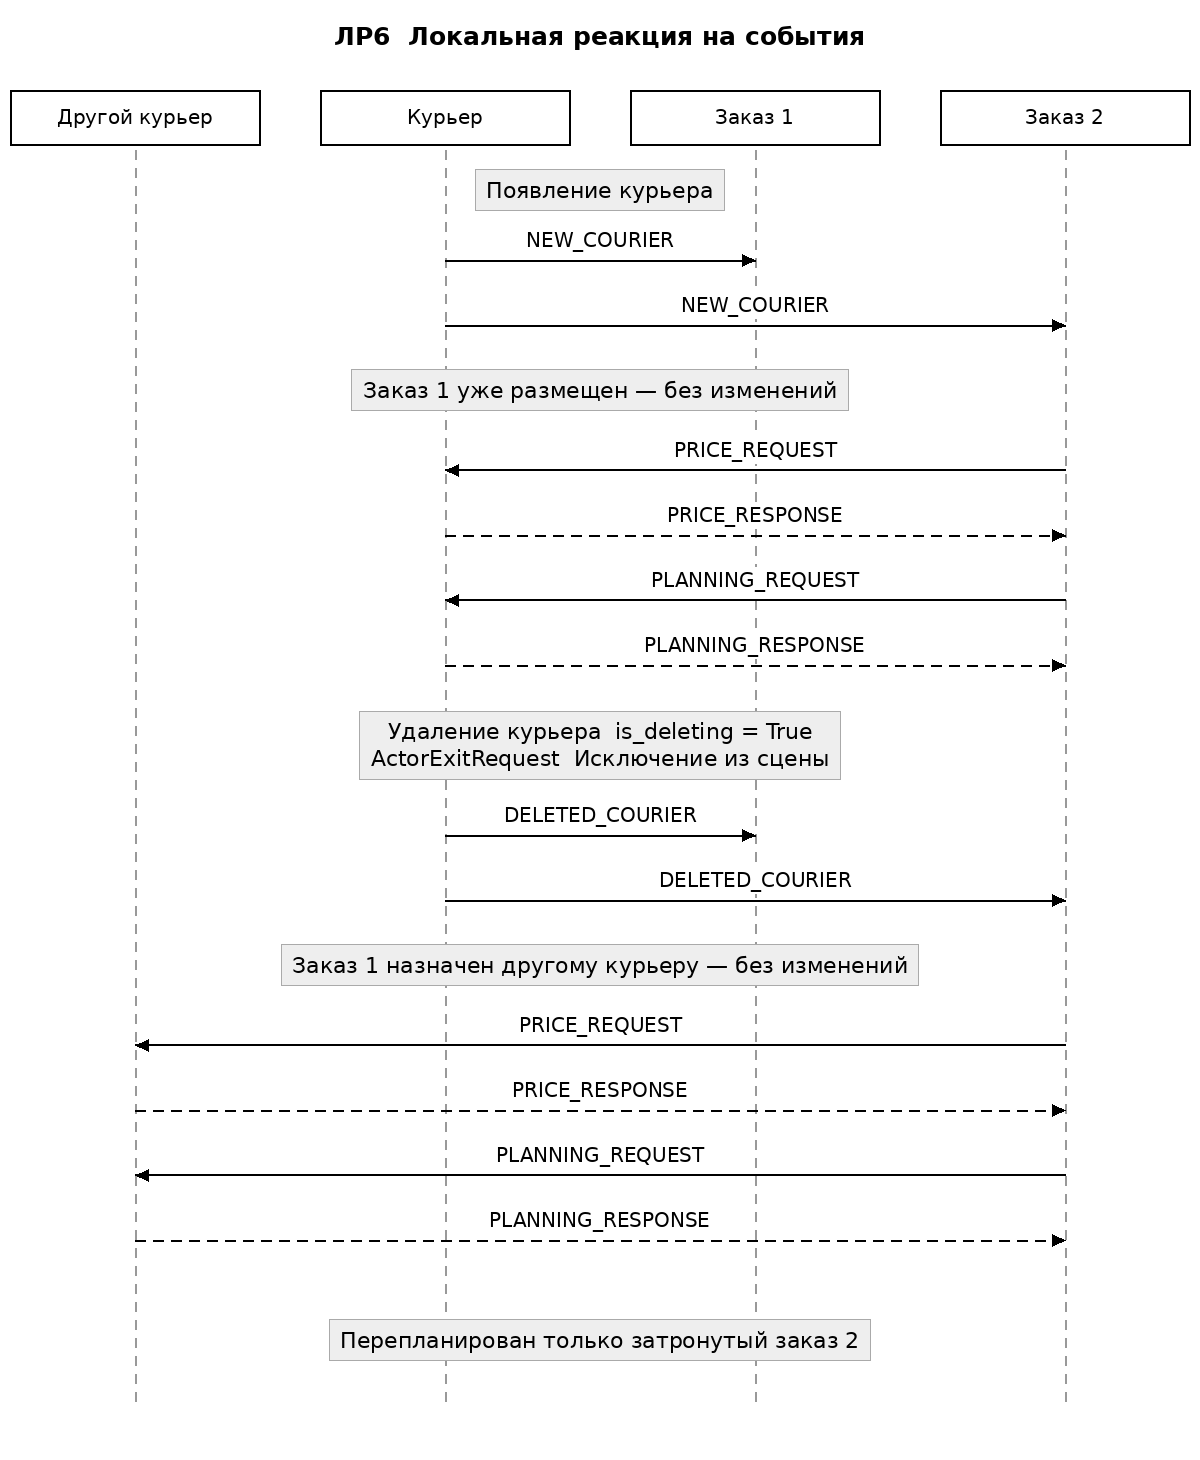

## 7 Удаление заказа и изменение параметров

После удаления заказа 2 новый заказ использует gap с 2 до 4; соседний заказ 3 не сдвигается. При сдвиге окна заказ 1 повторно оценивает варианты. Его маршрут может остаться прежним: мягкое окно и веса не гарантируют точное попадание в срок. Это показано в результатах, без подмены результата жестким ограничением. При уменьшении скорости с 5 до 2,5 перестраиваются три заказа этого курьера, стоимость возрастает с 6 до 12.

In [23]:
independent=run_independent()
print(json.dumps(independent,ensure_ascii=False,indent=2))


Удаление заказа {'Успех': True, 'Заказов в переговорах': 0, 'Курьеров в переговорах': 0, 'Агентов в перестройке': 1, 'Агентов получили сообщение': 1, 'Сообщений': 1}
Освободившийся интервал {'Вариант': 'gap', 'Начало': 2.0, 'Конец': 4.0, 'Соседний заказ сохранен': True}
Изменение окна {'Успех': True, 'Заказов в переговорах': 1, 'Курьеров в переговорах': 1, 'Агентов в перестройке': 2, 'Агентов получили сообщение': 2, 'Сообщений': 7, 'Показатели': {'Заказов': 3, 'Назначено': 3, 'В окне': 2, 'Стоимость': 6.0, 'Завершение плана': 6.0}}
Изменение скорости {'Успех': True, 'Заказов в переговорах': 3, 'Курьеров в переговорах': 1, 'Агентов в перестройке': 4, 'Агентов получили сообщение': 4, 'Сообщений': 18, 'Показатели': {'Заказов': 3, 'Назначено': 3, 'В окне': 2, 'Стоимость': 12.0, 'Завершение плана': 12.0}}
{
  "Удаление заказа": {
    "Успех": true,
    "Заказов в переговорах": 0,
    "Курьеров в переговорах": 0,
    "Агентов в перестройке": 1,
    "Агентов получили сообщение": 1,
    "Сообщ

## 8 Сравнение с полным пересчетом

Генерируются 50 заказов и 10 курьеров с random.Random(6). В обоих режимах используются одинаковые 10 событий: два новых заказа, новый курьер, изменение окна, изменение скорости, удаление заказа, удаление курьера, новый заказ, изменение окна и удаление курьера. В конце остаются 52 заказа и 9 курьеров.

Адаптивный режим сохраняет работающую систему. Полный режим после каждого события строит все назначения заново. perf_counter измеряет только обработку событий и построение плана: начальный план адаптивного режима, вывод, сохранение файлов, график и закрытие систем в время не включены. Логирование для обоих режимов отключено. Это один последовательный учебный прогон, не статистическое исследование производительности; миллисекунды при повторе изменятся.

Качество сравнивается по назначенным заказам, доставкам в окне, суммарной стоимости и времени завершения плана. Окно включает обе границы с допуском 1e-9.

**experiment.py**

In [24]:
"""Самостоятельная работа ЛР6: 50 заказов, 10 курьеров и 10 событий."""

import csv
import logging
import random
from pathlib import Path
from time import perf_counter



def experiment_data():
    rng = random.Random(6)
    couriers = [make_courier(i, types='Обычный;Срочный', velocity=rng.uniform(8, 12),
                             rate=rng.uniform(1, 2)) for i in range(1, 11)]
    orders = []
    for i in range(1, 51):
        row = make_order(i, pickup_x=rng.randint(1, 30), pickup_time=rng.randint(0, 20),
                         delivery_time=rng.randint(30, 70))
        row['Координата получения y'] = rng.randint(0, 20)
        orders.append(row)
    events = [
        {'action': 'add', 'entity_type': 'ORDER', 'data': make_order(51)},
        {'action': 'add', 'entity_type': 'ORDER', 'data': make_order(52, order_type='Срочный')},
        {'action': 'add', 'entity_type': 'COURIER',
         'data': make_courier(11, types='Обычный;Срочный', velocity=12, rate=0.8)},
        {'action': 'change', 'entity_type': 'ORDER', 'name': 'Заказ 5', 'changes': {'time_from': 10, 'time_to': 12}},
        {'action': 'change', 'entity_type': 'COURIER', 'name': 'Курьер 2', 'changes': {'velocity': 4}},
        {'action': 'remove', 'entity_type': 'ORDER', 'name': 'Заказ 7'},
        {'action': 'remove', 'entity_type': 'COURIER', 'name': 'Курьер 1'},
        {'action': 'add', 'entity_type': 'ORDER', 'data': make_order(53)},
        {'action': 'change', 'entity_type': 'ORDER', 'name': 'Заказ 15', 'changes': {'time_from': 5, 'time_to': 10}},
        {'action': 'remove', 'entity_type': 'COURIER', 'name': 'Курьер 3'},
    ]
    return couriers, orders, events


def change_input(couriers, orders, event):
    rows = couriers if event['entity_type'] == 'COURIER' else orders
    if event['action'] == 'add':
        rows.append(dict(event['data']))
        return
    name_key = 'ФИО' if event['entity_type'] == 'COURIER' else 'Наименование'
    row = next(r for r in rows if r[name_key] == event['name'])
    if event['action'] == 'remove':
        rows.remove(row)
    else:
        keys = {'velocity': 'Скорость', 'time_from': 'Время получения заказа', 'time_to': 'Время доставки заказа'}
        row.update({keys[k]: value for k, value in event['changes'].items()})


def run_experiment(config_file='planning_config.json', output_dir='Отчёты'):
    output_dir = Path(output_dir)
    output_dir.mkdir(exist_ok=True)
    _, criteria = load_planning_config(config_file)
    rows = []
    logger = logging.getLogger()
    old_level = logger.level
    logger.setLevel(logging.WARNING)
    try:
        for mode in ('Адаптивный', 'Полный пересчет'):
            couriers, orders, events = experiment_data()
            scene = dispatcher = None
            total_time = 0.0
            if mode == 'Адаптивный':
                scene, dispatcher = create_world(couriers, orders, criteria)
            try:
                for index, event in enumerate(events, 1):
                    start = perf_counter()
                    if mode == 'Адаптивный':
                        metrics = dispatcher.apply_event(event)
                    else:
                        change_input(couriers, orders, event)
                        scene, dispatcher = create_world(couriers, orders, criteria)
                        metrics = {'Заказов в переговорах': len(dispatcher.negotiating_orders),
                                   'Курьеров в переговорах': len(dispatcher.negotiating_couriers)}
                    elapsed = perf_counter() - start
                    total_time += elapsed
                    rows.append({'Режим': mode, 'Событие': index, 'Действие': event['action'],
                                 'Тип': event['entity_type'], 'Время мс': round(elapsed * 1000, 4),
                                 'Накопленное время мс': round(total_time * 1000, 4),
                                 'Заказов в переговорах': metrics['Заказов в переговорах'],
                                 'Курьеров в переговорах': metrics['Курьеров в переговорах'],
                                 **plan_quality(scene)})
                    if mode == 'Полный пересчет':
                        dispatcher.close()
                        dispatcher = None
            finally:
                if dispatcher is not None:
                    dispatcher.close()
    finally:
        logger.setLevel(old_level)
    with (output_dir / 'Эксперимент_ЛР6.csv').open('w', encoding='utf-8-sig', newline='') as file:
        writer = csv.DictWriter(file, fieldnames=list(rows[0]), delimiter=';')
        writer.writeheader()
        writer.writerows(rows)
    final = [r for r in rows if r['Событие'] == 10]
    with (output_dir / 'Сравнение_ЛР6.csv').open('w', encoding='utf-8-sig', newline='') as file:
        writer = csv.DictWriter(file, fieldnames=list(final[0]), delimiter=';')
        writer.writeheader()
        writer.writerows(final)
    draw_comparison(rows, output_dir / 'Сравнение_ЛР6.png')
    for row in final:
        print(row)
    return rows


def draw_comparison(rows, filename):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    figure = plt.figure(figsize=(7.5, 6.4))
    grid = figure.add_gridspec(2, 2)
    axes = [figure.add_subplot(grid[0, :]), figure.add_subplot(grid[1, 0]),
            figure.add_subplot(grid[1, 1])]
    for mode in ('Адаптивный', 'Полный пересчет'):
        data = [r for r in rows if r['Режим'] == mode]
        axes[0].plot([r['Событие'] for r in data], [r['Накопленное время мс'] for r in data], marker='o', label=mode)
    axes[0].set(xlabel='Номер события', ylabel='Накопленное время, мс', title='Время обработки 10 событий')
    final = [r for r in rows if r['Событие'] == 10]
    labels = ['Адаптивный', 'Полный\nпересчет']
    axes[1].bar(labels, [r['Стоимость'] for r in final], color=['#377ca8', '#d48b37'])
    axes[1].set(ylabel='Условные единицы', title='Итоговая стоимость')
    axes[2].bar(labels, [r['В окне'] for r in final], color=['#377ca8', '#d48b37'])
    axes[2].set(ylabel='Количество заказов', title='Доставки в окне')
    axes[0].legend(fontsize=8)
    for axis in axes:
        axis.spines[['top', 'right']].set_visible(False)
    figure.tight_layout()
    figure.savefig(filename, dpi=160)
    plt.close(figure)


In [25]:
experiment_rows=run_experiment()
print(Path('Отчёты/Сравнение_ЛР6.csv').read_text(encoding='utf-8-sig'))


{'Режим': 'Адаптивный', 'Событие': 10, 'Действие': 'remove', 'Тип': 'COURIER', 'Время мс': 0.8669, 'Накопленное время мс': 12.7951, 'Заказов в переговорах': 1, 'Курьеров в переговорах': 9, 'Заказов': 52, 'Назначено': 52, 'В окне': 36, 'Стоимость': 263.0476, 'Завершение плана': 49.8276}
{'Режим': 'Полный пересчет', 'Событие': 10, 'Действие': 'remove', 'Тип': 'COURIER', 'Время мс': 29.3594, 'Накопленное время мс': 336.3182, 'Заказов в переговорах': 52, 'Курьеров в переговорах': 9, 'Заказов': 52, 'Назначено': 52, 'В окне': 37, 'Стоимость': 274.7307, 'Завершение плана': 40.0611}
Режим;Событие;Действие;Тип;Время мс;Накопленное время мс;Заказов в переговорах;Курьеров в переговорах;Заказов;Назначено;В окне;Стоимость;Завершение плана
Адаптивный;10;remove;COURIER;0.8669;12.7951;1;9;52;52;36;263.0476;49.8276
Полный пересчет;10;remove;COURIER;29.3594;336.3182;52;9;52;52;37;274.7307;40.0611



| Режим | Время 10 событий мс | Стоимость | В окне | Назначено |
|---|---:|---:|---:|---:|
| Адаптивный | 12.7951 | 263.0476 | 36 | 52 |
| Полный пересчет | 336.3182 | 274.7307 | 37 | 52 |

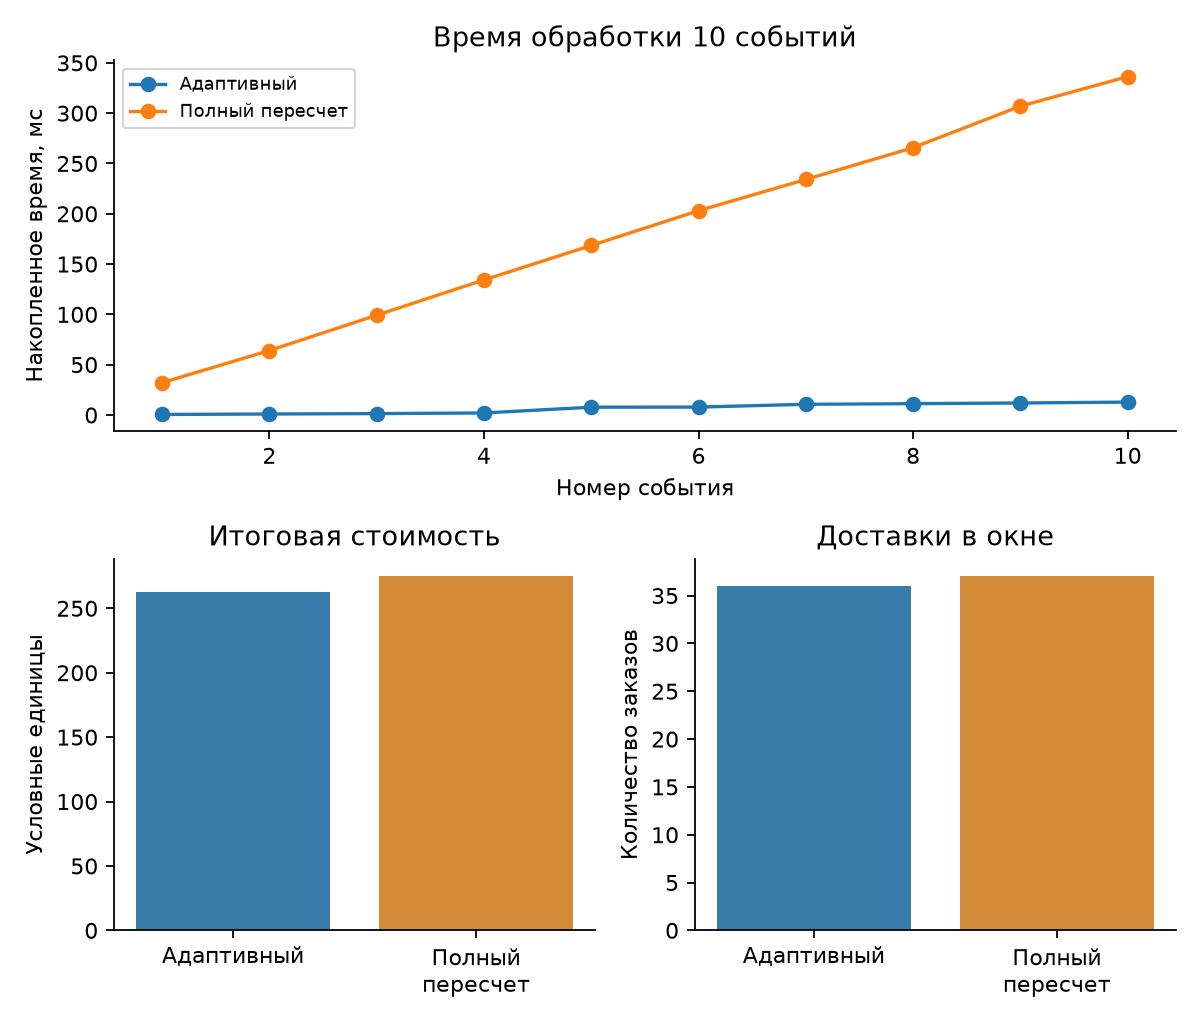

Полный пересчет может изменить незатронутые назначения и улучшить одни критерии за счет других. Адаптивный режим экономит работу, но не гарантирует лучший план по всем показателям. В данном наборе полная перестройка дает больше доставок в окне и более раннее завершение, адаптивная — меньшую стоимость.

## 9 Ответы на контрольные вопросы

**1 Чем пакетное планирование отличается от адаптивного**

Пакетный режим заново строит расписание по всем текущим данным. Адаптивный реагирует на отдельное событие и пересматривает затронутые назначения. Полный пересчет при частых событиях тратит время на неизменившиеся части и может закончиться уже после следующего изменения мира. В маленькой системе он допустим и здесь используется как режим сравнения.

**2 Почему новый заказ планируется сразу, а новому курьеру нужно уведомление**

Заказ уже начинает переговоры при инициализации: это его собственная цель. Курьер не является инициатором назначения заказа, поэтому его создание само по себе не запускает ранее отказавшиеся заказы. NEW_COURIER сообщает о новой возможности; только подходящие неразмещенные заказы повторяют поиск.

**3 Зачем нужен is_deleting**

Флаг исключает выбывающую сущность из выборки до завершения ее актора. Без него повторный опрос может снова выбрать удаляемого курьера или обратиться к исчезающему заказу. Диспетчер выставляет флаг перед ActorExitRequest, обработчик удаления также устанавливает его, а сцена фильтрует такие сущности.

**4 Как обеспечивается локальность перестройки**

При NEW_COURIER размещенный заказ ничего не меняет. При DELETED_COURIER поиск запускается только у заказов этого курьера. При изменении окна пересматривается заказ и, при нарушении связности, зависимый хвост маршрута; при изменении скорости — заказы этого ресурса. Измеряются участники переговоров, обслуживания события и получатели уведомлений: рассылка сообщения еще не означает перепланирование.

**5 Какие еще события полезны в логистике**

Отмена или изменение адреса доставки, изменение массы груза, опоздание получения, пробка, закрытие дороги, начало и окончание смены курьера, изменение доступности склада. Для каждого события нужно определить затронутые сущности, правила допустимости и способ согласования перестройки.

**6 Что мешает распределенному исполнению на нескольких машинах**

Сцена, сущности, адресная книга и черновики передаются по ссылкам в общей памяти simpleSystemBase. Между машинами такой общей памяти нет. Потребуются сериализуемые сообщения с идентификаторами, локальное владение данными, версии состояния и согласование фиксации; также обработка задержек, повторов и потерь соединений. В учебной версии события завершаются последовательно.

## Вывод

Система работает в событийном режиме и сохраняет незатронутые назначения. Реализованы три основных сценария, удаление заказа, изменения окна и скорости. Проведен требуемый эксперимент на 50 заказах, 10 курьерах и 10 событиях; таблица и график сохранены. Для интерактивной работы запустите `python main.py` или вызовите `main()` после определения функций в notebook.